# Fuzzy Vacation Planner
Aurélie Wasem

--- 

## Introduction

Combine two types of information:
- **Personality:** The traveler's general tendency toward adventurous experiences.
- **Current mood:** The traveler's current desire for relaxation during their next trip.

### Inputs

1. **Adventure-oriented personality (0–10)**
   - Relaxed
   - Balanced
   - Adventurous

2. **Current desire for relaxation (0–10)**
   - Low
   - Medium
   - High

### Output

**Recommended travel style (0–10)**

- Relaxing
- Balanced
- Adventurous

## Imports

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

## Fuzzy Variables and Membership Functions

### Define the fuzzy variables

In [19]:
# Input variables
personality = ctrl.Antecedent(
    np.arange(0, 10.1, 0.1),
    'personality'
)

relaxation = ctrl.Antecedent(
    np.arange(0, 10.1, 0.1),
    'relaxation'
)

# Output variable
travel_style = ctrl.Consequent(
    np.arange(0, 10.1, 0.1),
    'travel_style'
)


### Define the membership functions

In [20]:
# Personality membership functions
personality['relaxed'] = fuzz.trimf(
    personality.universe, [0, 0, 5]
)

personality['balanced'] = fuzz.trimf(
    personality.universe, [0, 5, 10]
)

personality['adventurous'] = fuzz.trimf(
    personality.universe, [5, 10, 10]
)

In [21]:
# Current relaxation desire
relaxation['low'] = fuzz.trimf(
    relaxation.universe, [0, 0, 5]
)

relaxation['medium'] = fuzz.trimf(
    relaxation.universe, [0, 5, 10]
)

relaxation['high'] = fuzz.trimf(
    relaxation.universe, [5, 10, 10]
)


In [22]:
# Recommended travel style

travel_style['relaxing'] = fuzz.trimf(
    travel_style.universe, [0, 0, 5]
)

travel_style['balanced'] = fuzz.trimf(
    travel_style.universe, [0, 5, 10]
)

travel_style['adventurous'] = fuzz.trimf(
    travel_style.universe, [5, 10, 10]
)


### Visualize the membership functions

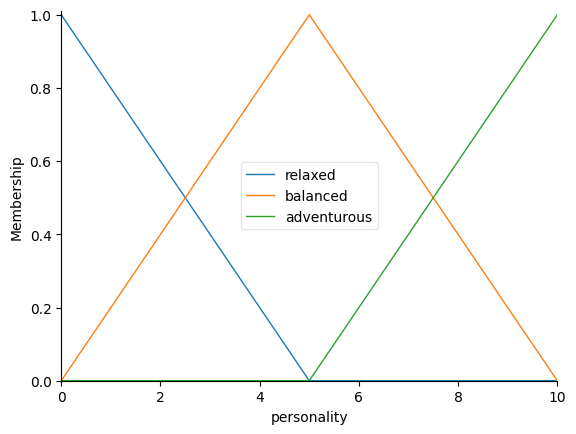

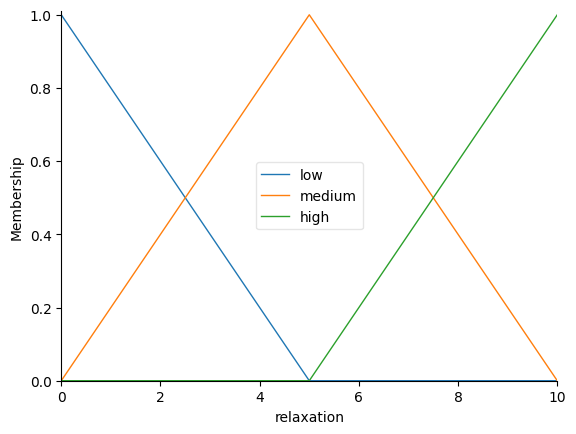

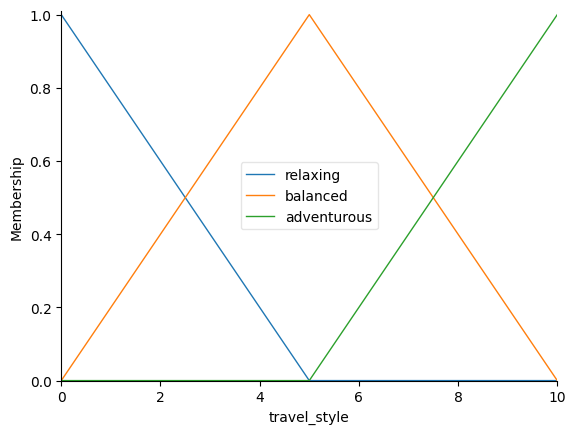

In [23]:
personality.view()
relaxation.view()
travel_style.view()

plt.show()


## Defining the Fuzzy Rules

Rule 1 — Relaxing trip
- IF personality is **relaxed** OR relaxation desire is **high**, THEN travel style is **relaxing**.


Rule 2 — Balanced trip
- IF personality is **balanced** OR relaxation desire is **medium**, THEN travel style is **balanced**.


Rule 3 — Adventurous trip
- IF personality is **adventurous** AND **relaxation** desire is low, THEN travel style is **adventurous**.


Rule 4 — Compromise
- IF personality is **adventurous** AND relaxation desire is **high**, THEN travel style is **balanced**.

In [24]:
# Rule 1: Relaxing trip
rule1 = ctrl.Rule(
    personality['relaxed'] | relaxation['high'],
    travel_style['relaxing']
)

# Rule 2: Balanced trip
rule2 = ctrl.Rule(
    personality['balanced'] | relaxation['medium'],
    travel_style['balanced']
)

# Rule 3: Adventurous trip
rule3 = ctrl.Rule(
    personality['adventurous'] & relaxation['low'],
    travel_style['adventurous']
)

# Rule 4: Compromise
rule4 = ctrl.Rule(
    personality['adventurous'] & relaxation['high'],
    travel_style['balanced']
)


### Control system

In [25]:
travel_ctrl = ctrl.ControlSystem([
    rule1,
    rule2,
    rule3,
    rule4
])

travel_simulation = ctrl.ControlSystemSimulation(
    travel_ctrl
)

print("Number of rules:", len(list(travel_ctrl.rules)))


Number of rules: 4


## Running and Visualizing the Fuzzy Simulation

In [26]:
# Define the input values
travel_simulation.input['personality'] = 8
travel_simulation.input['relaxation'] = 9

# Run the fuzzy inference system
travel_simulation.compute()

# Get the output
recommended_style = travel_simulation.output['travel_style']

print(f"Recommended travel style: {recommended_style:.2f}/10")


Recommended travel style: 4.11/10


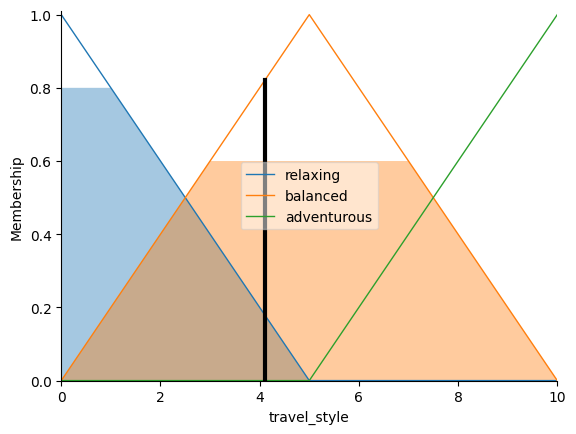

In [27]:
# Visualize the final output
travel_style.view(sim=travel_simulation)

plt.show()


## 5. Defuzzification

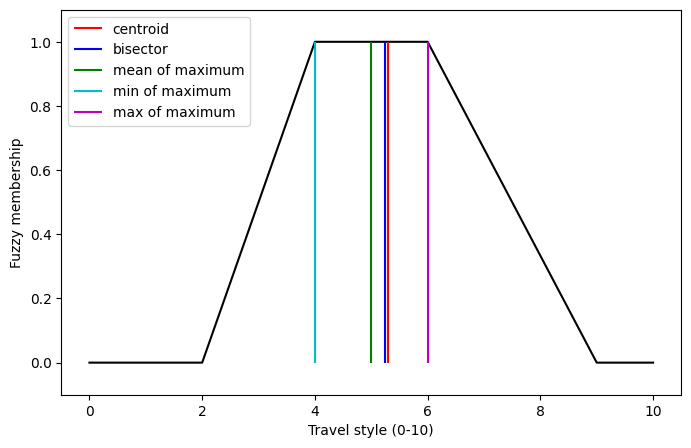

In [28]:
# Generate a trapezoidal membership function
x = np.arange(0, 10.1, 0.1)

mfx = fuzz.trapmf(x, [2, 4, 6, 9])


# Defuzzify using five different methods
defuzz_centroid = fuzz.defuzz(x, mfx, 'centroid')
defuzz_bisector = fuzz.defuzz(x, mfx, 'bisector')
defuzz_mom = fuzz.defuzz(x, mfx, 'mom')
defuzz_som = fuzz.defuzz(x, mfx, 'som')
defuzz_lom = fuzz.defuzz(x, mfx, 'lom')


# Collect information for the plot
labels = [
    'centroid',
    'bisector',
    'mean of maximum',
    'min of maximum',
    'max of maximum'
]

xvals = [
    defuzz_centroid,
    defuzz_bisector,
    defuzz_mom,
    defuzz_som,
    defuzz_lom
]

colors = ['r', 'b', 'g', 'c', 'm']

ymax = [
    fuzz.interp_membership(x, mfx, i)
    for i in xvals
]

# Display the membership function
plt.figure(figsize=(8, 5))
plt.plot(x, mfx, 'k')

# Display each defuzzification result
for xv, y, label, color in zip(
    xvals, ymax, labels, colors
):
    plt.vlines(
        xv, 0, y,
        label=label,
        color=color
    )

plt.ylabel('Fuzzy membership')
plt.xlabel('Travel style (0-10)')
plt.ylim(-0.1, 1.1)
plt.legend(loc=2)
plt.show()



In [29]:
# Print defuzzification results
for label, value in zip(labels, xvals):
    print(f"{label}: {value:.2f}")


centroid: 5.30
bisector: 5.25
mean of maximum: 5.00
min of maximum: 4.00
max of maximum: 6.00
